# Pertemuan 6 — Model Evaluation
### Praktik: menilai model klasifikasi dan regresi dengan jujur

<a href="https://colab.research.google.com/github/[username]/[nama-repo]/blob/main/pertemuan-06/06_Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Ganti `[username]` dan `[nama-repo]` pada tautan di atas (dan path di bagian 2) dengan alamat repositori atau folder Google Drive kelas.

**Setelah menyelesaikan notebook ini, kamu bisa:**

1. Membaca confusion matrix dengan istilah **TP, FP, FN, TN**.
2. Menghitung dan menjelaskan **precision**, **recall**, dan **F1**, serta memilih yang paling sesuai kebutuhan bisnis.
3. Menjelaskan kenapa **akurasi bisa turun** padahal model menjadi lebih berguna.
4. Membaca **kurva ROC** dan **AUC**, **kurva precision-recall**, dan **kurva gain**.
5. Menilai model regresi dengan **MAE**, **RMSE**, **R²**, dan **MAPE**, termasuk jebakan masing-masing.
6. Membaca **residual** dan mencari di mana model paling sering meleset.
7. Menyusun **kartu skor model** untuk orang non-teknis.

**Dataset:** `prediksi_response_uji.csv` (hasil Pertemuan 5) dan `marketing_segmen.csv` (hasil Pertemuan 4).

**Perkiraan waktu:** 70–80 menit.

---
## 1. Business case: "87,7% itu bagus, kan?"

Masih **Juli 2014** di *RetailKu* (perusahaan fiktif). Kamu mempresentasikan model Pertemuan 5 di rapat direksi. Kalimat pertamamu: *"Model kita 87,7% akurat."* Dua orang langsung bertanya:

> **Manajer marketing:** *"Dari semua pelanggan yang sebenarnya mau merespons, berapa yang berhasil ditemukan model? Saya tidak mau kehilangan mereka."*
>
> **Direktur keuangan:** *"Setiap penawaran ada biayanya. Dari pelanggan yang dipilih model, berapa yang benar-benar merespons? Saya tidak mau buang uang."*

Akurasi tidak menjawab keduanya. Hari ini kita belajar **ukuran yang menjawab pertanyaan bisnis**.

| Pertanyaan bisnis | Ukuran |
|---|---|
| Dari semua responden, berapa yang ditemukan? | **Recall** |
| Dari yang dipilih model, berapa yang benar? | **Precision** |
| Bagaimana menyeimbangkan keduanya? | **F1** |
| Seberapa baik model **mengurutkan** pelanggan, apa pun batasnya? | **ROC-AUC**, kurva precision-recall, kurva gain |
| Rata-rata perkiraan belanja meleset berapa? | **MAE**, **RMSE** |
| Seberapa jauh lebih baik daripada menebak rata-rata? | **R²** |

> Hari ini kita **menilai**. Memilih batas peluang terbaik, *cross-validation*, dan *tuning* dibahas di Pertemuan 7.

---
## 2. Menyiapkan alat dan data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

WARNA = "#2B6F7E"
WARNA_SOROT = "#B4501F"
WARNA_ABU = "#8A9BA8"
WARNA_EMAS = "#D9A441"

from matplotlib.colors import LinearSegmentedColormap
PETA_TEAL = LinearSegmentedColormap.from_list("teal", ["#F4F7F8", WARNA])

In [2]:
# Hubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Tentukan folder tempat Anda menyimpan file hasil Pertemuan 4 dan 5 di Google Drive
FOLDER = '/content/drive/MyDrive/UNIPA 2026/Meet 6/'

prediksi = pd.read_csv(FOLDER + 'prediksi_response_uji.csv')   # hasil Pertemuan 5
df = pd.read_csv(FOLDER + 'marketing_segmen.csv')              # hasil Pertemuan 4
print("prediksi:", prediksi.shape, "| df:", df.shape)

Mounted at /content/drive
prediksi: (406, 7) | df: (2026, 39)


In [3]:
prediksi.head()

,ID,Response,peluang_logreg,peluang_hutan,tebakan_logreg,tebakan_pohon,tebakan_hutan
0,3270,0,0.0270,0.1333,0,0,0
1,5868,0,0.0278,0.0100,0,0,0
2,2793,0,0.2026,0.0433,0,0,0
3,916,0,0.0159,0.0389,0,0,0
4,5687,0,0.0407,0.2475,0,0,0


💬 **Amati:** untuk menilai model, kita **tidak perlu melatih ulang**. Cukup dua hal: **jawaban sebenarnya** (`Response`) dan **tebakan model** (`tebakan_...` atau `peluang_...`). Semua ukuran hari ini dihitung dari dua kolom itu.

---
## 3. Confusion matrix dengan nama resminya

Di Pertemuan 5 kita memakai bahasa bisnis. Sekarang kita pakai istilah resminya. Kelas yang kita cari (merespons = 1) disebut **positif**.

| | Ditebak 0 (negatif) | Ditebak 1 (positif) |
|---|---|---|
| **Sebenarnya 0** | **TN** · *true negative* · benar diabaikan | **FP** · *false positive* · penawaran terbuang |
| **Sebenarnya 1** | **FN** · *false negative* · responden terlewat | **TP** · *true positive* · responden tertangkap |

Cara mengingat: huruf kedua (**P/N**) = tebakan model; huruf pertama (**T/F**) = tebakannya benar atau salah.

TN = 332  (benar diabaikan)
FP = 12   (penawaran terbuang)
FN = 38   (responden terlewat)
TP = 24   (responden tertangkap)


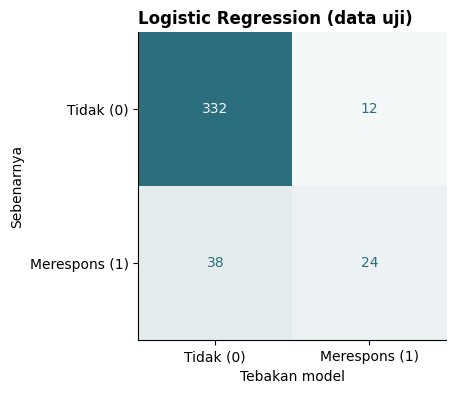

In [4]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_uji = prediksi["Response"]
tebakan = prediksi["tebakan_logreg"]

tn, fp, fn, tp = confusion_matrix(y_uji, tebakan).ravel()
print(f"TN = {tn}  (benar diabaikan)")
print(f"FP = {fp}   (penawaran terbuang)")
print(f"FN = {fn}   (responden terlewat)")
print(f"TP = {tp}   (responden tertangkap)")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_uji, tebakan, display_labels=["Tidak (0)", "Merespons (1)"],
                                        cmap=PETA_TEAL, colorbar=False, ax=ax)
ax.set_title("Logistic Regression (data uji)", loc="left", fontweight="bold")
ax.set_xlabel("Tebakan model")
ax.set_ylabel("Sebenarnya")
ax.grid(False)
plt.show()

---
## 4. Precision, recall, dan F1

### 4.1 Tiga rumus, tiga pertanyaan

| Ukuran | Rumus | Pertanyaan yang dijawab | Siapa yang peduli |
|---|---|---|---|
| **Precision** | TP / (TP + FP) | Dari yang **ditebak** merespons, berapa persen yang benar? | Direktur keuangan |
| **Recall** | TP / (TP + FN) | Dari yang **sebenarnya** merespons, berapa persen yang ditemukan? | Manajer marketing |
| **F1** | 2 × P × R / (P + R) | Satu angka yang menyeimbangkan keduanya | Saat keduanya sama penting |

Recall adalah "% responden tertangkap" dari Pertemuan 5. Mari hitung manual dulu, lalu cocokkan dengan scikit-learn.

In [5]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

precision_manual = tp / (tp + fp)
recall_manual = tp / (tp + fn)
f1_manual = 2 * precision_manual * recall_manual / (precision_manual + recall_manual)
akurasi_manual = (tp + tn) / (tp + tn + fp + fn)

pd.DataFrame({
    "manual": [akurasi_manual, precision_manual, recall_manual, f1_manual],
    "scikit-learn": [accuracy_score(y_uji, tebakan), precision_score(y_uji, tebakan),
                     recall_score(y_uji, tebakan), f1_score(y_uji, tebakan)],
}, index=["akurasi", "precision", "recall", "F1"]).round(3)

,manual,scikit-learn
akurasi,0.877,0.877
precision,0.667,0.667
recall,0.387,0.387
F1,0.490,0.490


💬 **Terjemahkan ke bahasa bisnis:** lengkapi kalimat berikut dengan angka di atas.

- *"Dari setiap 100 pelanggan yang dipilih model, sekitar ___ benar-benar merespons."* (precision)
- *"Model menemukan ___ dari setiap 100 pelanggan yang sebenarnya mau merespons."* (recall)

### 4.2 Kenapa F1 memakai rata-rata harmonik?

Rata-rata biasa bisa menipu. Bayangkan model malas versi kebalikan: **semua** pelanggan ditebak merespons.

In [6]:
semua_satu = np.ones(len(y_uji), dtype=int)
p_semua = precision_score(y_uji, semua_satu)
r_semua = recall_score(y_uji, semua_satu)

print(f"Precision          : {p_semua:.3f}")
print(f"Recall             : {r_semua:.3f}")
print(f"Rata-rata biasa    : {(p_semua + r_semua) / 2:.3f}")
print(f"F1 (rata harmonik) : {f1_score(y_uji, semua_satu):.3f}")

Precision          : 0.153
Recall             : 1.000
Rata-rata biasa    : 0.576
F1 (rata harmonik) : 0.265


💬 **Amati:** recall sempurna (semua responden pasti tertangkap), tapi precision hanya 15%. Rata-rata biasa memberi nilai lumayan; F1 menghukum ketimpangan itu. F1 hanya tinggi jika **keduanya** tinggi.

### 4.3 Membandingkan tiga model dengan ukuran baru

In [7]:
def kartu_klasifikasi(nama, y_benar, y_tebak):
    return {
        "model": nama,
        "akurasi": accuracy_score(y_benar, y_tebak),
        "precision": precision_score(y_benar, y_tebak, zero_division=0),
        "recall": recall_score(y_benar, y_tebak),
        "F1": f1_score(y_benar, y_tebak),
    }

tabel = pd.DataFrame([
    kartu_klasifikasi("Model malas (semua 0)", y_uji, np.zeros(len(y_uji), dtype=int)),
    kartu_klasifikasi("Logistic Regression", y_uji, prediksi["tebakan_logreg"]),
    kartu_klasifikasi("Decision Tree (depth 3)", y_uji, prediksi["tebakan_pohon"]),
    kartu_klasifikasi("Random Forest", y_uji, prediksi["tebakan_hutan"]),
]).set_index("model").round(3)
tabel

,akurasi,precision,recall,F1
model,,,,
Model malas (semua 0),0.847,0.000,0.000,0.000
Logistic Regression,0.877,0.667,0.387,0.490
Decision Tree (depth 3),0.860,0.564,0.355,0.436
Random Forest,0.865,0.606,0.323,0.421


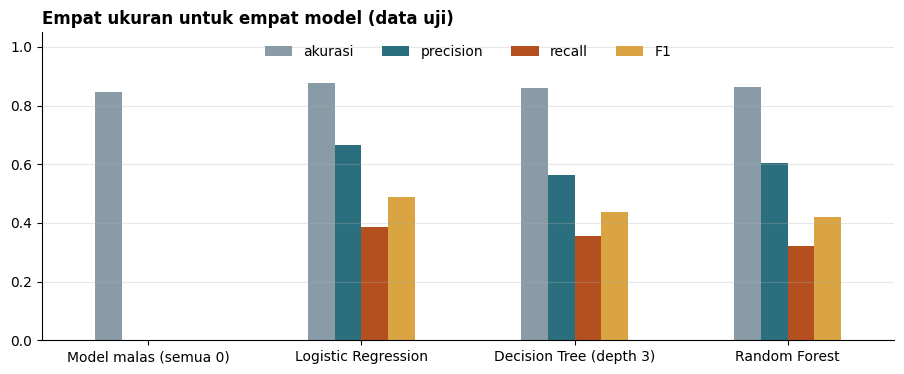

In [8]:
ax = tabel[["akurasi", "precision", "recall", "F1"]].plot(kind="bar", rot=0, figsize=(11, 4),
                                                         color=[WARNA_ABU, WARNA, WARNA_SOROT, WARNA_EMAS])
ax.set_title("Empat ukuran untuk empat model (data uji)", loc="left", fontweight="bold")
ax.set_ylim(0, 1.05)
ax.set_xlabel("")
ax.legend(ncol=4, loc="upper center", frameon=False)
ax.grid(axis="x", visible=False)
plt.show()

💬 **Diskusi:**

1. Model malas punya akurasi tertinggi kedua. Bagaimana precision, recall, dan F1-nya?
2. Model mana yang terbaik menurut F1? Apakah sama dengan yang terbaik menurut akurasi?

### 4.4 Ukuran mana yang dipakai? Tergantung biaya kesalahan

| Situasi | Kesalahan yang paling mahal | Utamakan |
|---|---|---|
| Filter spam email | Email penting masuk spam (FP) | Precision |
| Skrining penyakit serius | Pasien sakit dinyatakan sehat (FN) | Recall |
| Kampanye RetailKu lewat email (murah) | Responden terlewat (FN) | ? |
| Kampanye RetailKu lewat katalog cetak + hadiah (mahal) | Penawaran terbuang (FP) | ? |

<details>
<summary><b>Penjelasan</b></summary>

Email hampir gratis, jadi lebih baik mengirim ke lebih banyak orang daripada kehilangan responden: utamakan **recall**. Katalog cetak dan hadiah mahal, jadi setiap penawaran terbuang merugikan: utamakan **precision**. Di Pertemuan 7, pilihan ini dihitung dengan biaya dan keuntungan yang sebenarnya.

</details>

### 4.5 `classification_report`: semua sekaligus

In [9]:
from sklearn.metrics import classification_report

print(classification_report(y_uji, prediksi["tebakan_logreg"], target_names=["Tidak (0)", "Merespons (1)"], digits=3))

               precision    recall  f1-score   support

    Tidak (0)      0.897     0.965     0.930       344
Merespons (1)      0.667     0.387     0.490        62

     accuracy                          0.877       406
    macro avg      0.782     0.676     0.710       406
 weighted avg      0.862     0.877     0.863       406



💬 **Cara membaca:** setiap baris menghitung precision, recall, dan F1 dengan menganggap kelas itu sebagai "positif". `support` = jumlah data sebenarnya di kelas itu. Untuk kasus kita, baris **Merespons (1)** yang paling penting.

---
## 5. Akurasi turun, tapi model lebih berguna

Model Pertemuan 5 dilatih dengan data yang 85% berisi "tidak merespons", sehingga cenderung "malas" menebak 1. Opsi `class_weight="balanced"` membuat setiap kesalahan pada kelas kecil **dihitung lebih berat** saat belajar.

Kita perlu melatih ulang, jadi kita susun ulang pipeline dan pembagian data Pertemuan 5 dengan ringkas.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression

URUTAN_PENDIDIKAN = ["Basic", "Graduation", "Master", "PhD"]
FITUR_ANGKA = ["Income", "Age", "Tenure_days", "Recency", "Children", "TotalSpend_log",
               "TotalPurchases", "AvgSpendPerPurchase", "NumDealsPurchases",
               "NumWebVisitsMonth", "TotalAcceptedPrev", "Complain"]
FITUR_KATEGORI = ["Education", "Marital_Status"]

def buat_persiapan(fitur_angka, scaling=True):
    langkah_angka = [("isi_kosong", SimpleImputer(strategy="median"))]
    if scaling:
        langkah_angka.append(("skala", StandardScaler()))
    return ColumnTransformer([
        ("angka", Pipeline(langkah_angka), fitur_angka),
        ("ordinal", OrdinalEncoder(categories=[URUTAN_PENDIDIKAN],
                                   handle_unknown="use_encoded_value", unknown_value=-1), ["Education"]),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Marital_Status"]),
    ], verbose_feature_names_out=False)

X = df[FITUR_ANGKA + FITUR_KATEGORI]
y = df["Response"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Pastikan data uji sama persis dengan Pertemuan 5
print("Data uji sama dengan Pertemuan 5:", (df.loc[X_test.index, "ID"].values == prediksi["ID"].values).all())

Data uji sama dengan Pertemuan 5: True


In [11]:
model_biasa = Pipeline([("persiapan", buat_persiapan(FITUR_ANGKA)),
                        ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
model_seimbang = Pipeline([("persiapan", buat_persiapan(FITUR_ANGKA)),
                           ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(X_train, y_train)

tebakan_seimbang = model_seimbang.predict(X_test)

banding = pd.DataFrame([
    kartu_klasifikasi("LogReg biasa", y_test, model_biasa.predict(X_test)),
    kartu_klasifikasi('LogReg class_weight="balanced"', y_test, tebakan_seimbang),
]).set_index("model").round(3)
banding

,akurasi,precision,recall,F1
model,,,,
LogReg biasa,0.877,0.667,0.387,0.490
"LogReg class_weight=""balanced""",0.796,0.409,0.758,0.531


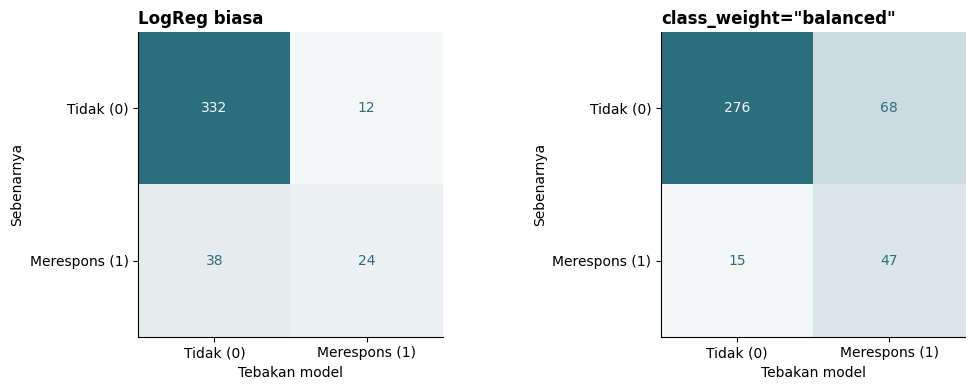

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (judul, tebak) in zip(axes, [("LogReg biasa", model_biasa.predict(X_test)),
                                     ('class_weight="balanced"', tebakan_seimbang)]):
    ConfusionMatrixDisplay.from_predictions(y_test, tebak, display_labels=["Tidak (0)", "Merespons (1)"],
                                            cmap=PETA_TEAL, colorbar=False, ax=ax)
    ax.set_title(judul, loc="left", fontweight="bold")
    ax.set_xlabel("Tebakan model")
    ax.set_ylabel("Sebenarnya")
    ax.grid(False)
plt.tight_layout()
plt.show()

💬 **Diskusi:**

1. Akurasi turun berapa poin? Recall naik berapa kali lipat?
2. Bandingkan kotak TP dan FP pada kedua confusion matrix. Apa yang "dibayar" untuk menangkap lebih banyak responden?
3. Untuk kampanye email (murah), model mana yang kamu pilih? Untuk kampanye katalog (mahal)?

> **Pelajaran utama:** model dengan akurasi lebih rendah bisa lebih berguna. Selalu pilih ukuran berdasarkan **biaya kesalahan**, bukan kebiasaan.

---
## 6. Peluang dan batas keputusan

`predict()` memakai batas (*threshold*) 0,5: peluang ≥ 0,5 → tebak 1. Batas itu bisa digeser. Setiap batas menghasilkan confusion matrix yang berbeda.

In [13]:
peluang = prediksi["peluang_logreg"]

baris = []
for batas in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    tebak = (peluang >= batas).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_uji, tebak).ravel()
    baris.append({"batas": batas, "dikirimi": tp_ + fp_, "TP": tp_, "FP": fp_, "FN": fn_,
                  "precision": precision_score(y_uji, tebak, zero_division=0),
                  "recall": recall_score(y_uji, tebak)})
tabel_batas = pd.DataFrame(baris).round(3)
tabel_batas

,batas,dikirimi,TP,FP,FN,precision,recall
0,0.1,157,55,102,7,0.350,0.887
1,0.2,100,45,55,17,0.450,0.726
2,0.3,74,41,33,21,0.554,0.661
3,0.4,46,29,17,33,0.630,0.468
4,0.5,36,24,12,38,0.667,0.387
5,0.6,27,19,8,43,0.704,0.306
6,0.7,17,13,4,49,0.765,0.210
7,0.8,11,10,1,52,0.909,0.161


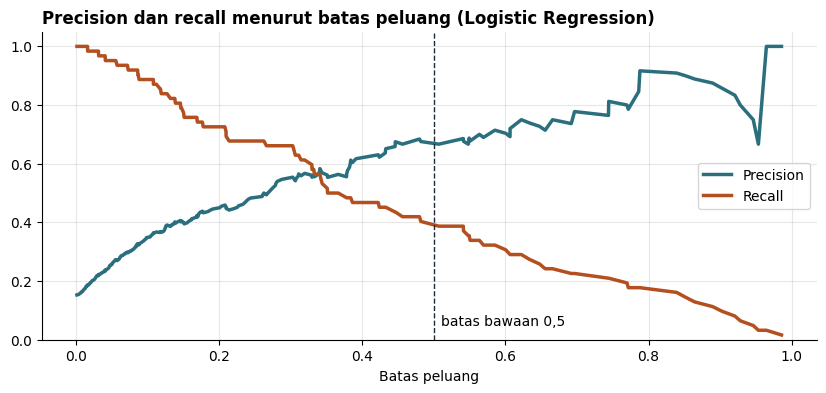

In [14]:
from sklearn.metrics import precision_recall_curve

p_kurva, r_kurva, batas_kurva = precision_recall_curve(y_uji, peluang)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(batas_kurva, p_kurva[:-1], color=WARNA, linewidth=2.5, label="Precision")
ax.plot(batas_kurva, r_kurva[:-1], color=WARNA_SOROT, linewidth=2.5, label="Recall")
ax.axvline(0.5, color="#1B2A35", linestyle="--", linewidth=1)
ax.text(0.51, 0.05, "batas bawaan 0,5")
ax.set_title("Precision dan recall menurut batas peluang (Logistic Regression)", loc="left", fontweight="bold")
ax.set_xlabel("Batas peluang")
ax.set_ylim(0, 1.05)
ax.legend()
plt.show()

💬 **Amati:** saat batas diturunkan, apa yang terjadi pada recall? Pada precision? Kenapa keduanya bergerak berlawanan arah?

Tidak ada batas yang "benar" secara umum. Batas terbaik bergantung pada biaya penawaran dan keuntungan dari setiap respons. **Pertemuan 7** menghitungnya.

---
## 7. Menilai urutan, bukan satu batas: ROC dan AUC

Precision dan recall berubah-ubah tergantung batas. Bagaimana menilai model **tanpa** memilih batas dulu? Lihat seberapa baik model **mengurutkan** pelanggan.

### 7.1 Kurva ROC

Untuk setiap batas, hitung dua angka:

- **True positive rate (TPR)** = recall = TP / (TP + FN): responden yang tertangkap.
- **False positive rate (FPR)** = FP / (FP + TN): non-responden yang ikut terpilih.

Kurva ROC menghubungkan semua pasangan (FPR, TPR). Model sempurna naik lurus ke pojok kiri atas; tebakan acak berada di garis diagonal.

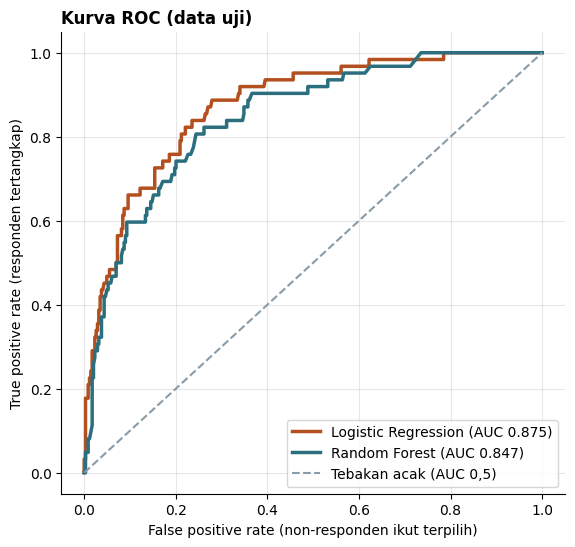

In [15]:
from sklearn.metrics import roc_curve, roc_auc_score

fig, ax = plt.subplots(figsize=(6.5, 6))
for nama, kolom, warna in [("Logistic Regression", "peluang_logreg", WARNA_SOROT),
                           ("Random Forest", "peluang_hutan", WARNA)]:
    fpr, tpr, _ = roc_curve(y_uji, prediksi[kolom])
    auc = roc_auc_score(y_uji, prediksi[kolom])
    ax.plot(fpr, tpr, color=warna, linewidth=2.5, label=f"{nama} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], color=WARNA_ABU, linestyle="--", label="Tebakan acak (AUC 0,5)")
ax.set_title("Kurva ROC (data uji)", loc="left", fontweight="bold")
ax.set_xlabel("False positive rate (non-responden ikut terpilih)")
ax.set_ylabel("True positive rate (responden tertangkap)")
ax.legend(loc="lower right")
plt.show()

### 7.2 Arti AUC dalam satu kalimat

**AUC** (*area under the curve*) adalah luas di bawah kurva ROC, dari 0,5 (acak) sampai 1 (sempurna). Artinya yang paling mudah dijelaskan:

> **Jika kita ambil satu responden dan satu non-responden secara acak, AUC adalah peluang model memberi skor lebih tinggi kepada si responden.**

Kita buktikan dengan menghitung langsung semua pasangan.

In [16]:
skor_responden = peluang[y_uji == 1].values
skor_bukan = peluang[y_uji == 0].values

semua_pasangan = skor_responden[:, None] > skor_bukan[None, :]     # 62 × 344 pasangan
seri = skor_responden[:, None] == skor_bukan[None, :]
peluang_menang = (semua_pasangan.sum() + 0.5 * seri.sum()) / semua_pasangan.size

print(f"Jumlah pasangan             : {semua_pasangan.size:,}")
print(f"Responden diberi skor lebih tinggi: {peluang_menang:.3f}")
print(f"roc_auc_score               : {roc_auc_score(y_uji, peluang):.3f}")

Jumlah pasangan             : 21,328
Responden diberi skor lebih tinggi: 0.875
roc_auc_score               : 0.875


💬 **Amati:** kedua angka sama. Jadi AUC 0,875 berarti: dari 100 pasangan acak (satu responden, satu non-responden), model mengurutkan sekitar 87–88 pasangan dengan benar.

### 7.3 Kurva precision-recall: lebih jujur untuk kelas kecil

Kurva ROC bisa terlihat bagus walau precision rendah, karena FPR dibagi dengan jumlah non-responden yang besar. Untuk kelas yang jarang, **kurva precision-recall** dan **average precision (AP)** sering lebih informatif. Baseline-nya bukan 0,5, melainkan **persentase kelas positif** (sekitar 0,15).

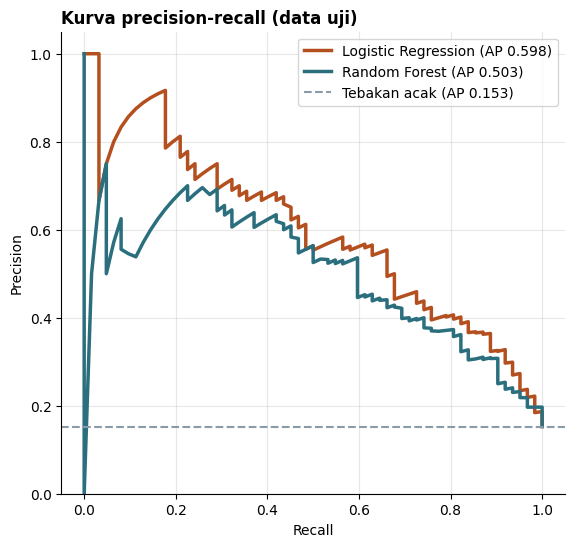

In [17]:
from sklearn.metrics import average_precision_score

fig, ax = plt.subplots(figsize=(6.5, 6))
for nama, kolom, warna in [("Logistic Regression", "peluang_logreg", WARNA_SOROT),
                           ("Random Forest", "peluang_hutan", WARNA)]:
    p_, r_, _ = precision_recall_curve(y_uji, prediksi[kolom])
    ap = average_precision_score(y_uji, prediksi[kolom])
    ax.plot(r_, p_, color=warna, linewidth=2.5, label=f"{nama} (AP {ap:.3f})")
ax.axhline(y_uji.mean(), color=WARNA_ABU, linestyle="--", label=f"Tebakan acak (AP {y_uji.mean():.3f})")
ax.set_title("Kurva precision-recall (data uji)", loc="left", fontweight="bold")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_ylim(0, 1.05)
ax.legend(loc="upper right")
plt.show()

### 7.4 Kurva gain: versi untuk rapat direksi

Kurva gain menjawab: *"Jika kita menghubungi X% pelanggan dengan peluang tertinggi, berapa persen responden yang tertangkap?"* Ini perluasan dari daftar prioritas di Pertemuan 5.

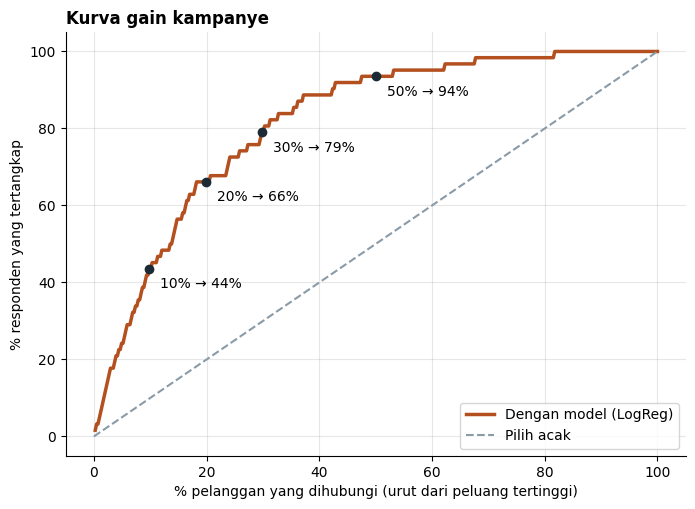

In [18]:
urutan = np.argsort(-peluang.values)
y_urut = y_uji.values[urutan]
persen_dihubungi = np.arange(1, len(y_urut) + 1) / len(y_urut) * 100
persen_tertangkap = np.cumsum(y_urut) / y_urut.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(persen_dihubungi, persen_tertangkap, color=WARNA_SOROT, linewidth=2.5, label="Dengan model (LogReg)")
ax.plot([0, 100], [0, 100], color=WARNA_ABU, linestyle="--", label="Pilih acak")
for p in [10, 20, 30, 50]:
    i = int(len(y_urut) * p / 100) - 1
    ax.scatter(persen_dihubungi[i], persen_tertangkap[i], color="#1B2A35", zorder=3)
    ax.annotate(f"{p}% → {persen_tertangkap[i]:.0f}%", (persen_dihubungi[i], persen_tertangkap[i]),
                textcoords="offset points", xytext=(8, -14))
ax.set_title("Kurva gain kampanye", loc="left", fontweight="bold")
ax.set_xlabel("% pelanggan yang dihubungi (urut dari peluang tertinggi)")
ax.set_ylabel("% responden yang tertangkap")
ax.legend(loc="lower right")
plt.show()

💬 **Diskusi:** dengan menghubungi setengah pelanggan, berapa persen responden yang tertangkap? Kalimat mana yang lebih mudah dipahami direksi: *"AUC kita 0,875"* atau *"Dengan menghubungi 30% pelanggan, kita menjangkau hampir 80% responden"*?

---
## 8. Menilai model regresi

### 8.1 Menyiapkan ulang model regresi Pertemuan 5

In [19]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

FITUR_PROFIL = ["Income", "Age", "Children", "Tenure_days"]
X_reg = df[FITUR_PROFIL + FITUR_KATEGORI]
y_reg = df["TotalSpend"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

model_reg = {
    "Model malas (rata-rata)": DummyRegressor(strategy="mean").fit(Xr_train, yr_train),
    "Linear Regression": Pipeline([("persiapan", buat_persiapan(FITUR_PROFIL)),
                                   ("model", LinearRegression())]).fit(Xr_train, yr_train),
    "Random Forest": Pipeline([("persiapan", buat_persiapan(FITUR_PROFIL, scaling=False)),
                               ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                               random_state=42))]).fit(Xr_train, yr_train),
}
tebakan_reg = {nama: m.predict(Xr_test) for nama, m in model_reg.items()}
print("Data uji regresi:", len(yr_test), "pelanggan")

Data uji regresi: 406 pelanggan


### 8.2 Empat ukuran regresi

| Ukuran | Rumus | Arti | Jebakan |
|---|---|---|---|
| **MAE** | rata-rata \|y − ŷ\| | Rata-rata meleset, dalam satuan target | Tidak membedakan meleset besar dan kecil |
| **RMSE** | √ rata-rata (y − ŷ)² | Seperti MAE, tetapi **menghukum meleset besar** | Sangat terpengaruh beberapa kesalahan besar |
| **R²** | 1 − SS_res / SS_tot | Seberapa jauh lebih baik daripada menebak rata-rata | Tidak memberi tahu besar meleset dalam satuan |
| **MAPE** | rata-rata \|y − ŷ\| / \|y\| | Meleset dalam **persen** | Meledak jika nilai sebenarnya kecil |

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

def kartu_regresi(nama, y_benar, y_tebak):
    return {
        "model": nama,
        "MAE": mean_absolute_error(y_benar, y_tebak),
        "RMSE": np.sqrt(mean_squared_error(y_benar, y_tebak)),
        "R2": r2_score(y_benar, y_tebak),
        "MAPE_%": mean_absolute_percentage_error(y_benar, y_tebak) * 100,
        "tebakan_negatif": int((y_tebak < 0).sum()),
    }

tabel_reg = pd.DataFrame([kartu_regresi(n, yr_test, t) for n, t in tebakan_reg.items()]).set_index("model").round(2)
tabel_reg

,MAE,RMSE,R2,MAPE_%,tebakan_negatif
model,,,,,
Model malas (rata-rata),524.34,613.47,-0.00,543.22,0
Linear Regression,236.89,303.64,0.75,181.78,39
Random Forest,185.85,269.65,0.81,84.13,0


💬 **Amati:**

1. RMSE selalu lebih besar atau sama dengan MAE. Kenapa? Apa artinya jika RMSE **jauh** lebih besar daripada MAE?
2. MAPE Linear Regression lebih dari 100%. Apakah modelnya memang separah itu, padahal R²-nya 0,76?

### 8.3 Jebakan MAPE: pembagi yang kecil

In [21]:
hasil = pd.DataFrame({"sebenarnya": yr_test.values,
                      "tebakan": tebakan_reg["Linear Regression"]})
hasil["meleset"] = (hasil["sebenarnya"] - hasil["tebakan"]).abs()
hasil["meleset_%"] = hasil["meleset"] / hasil["sebenarnya"] * 100

print("Lima pelanggan dengan meleset_% terbesar:")
display(hasil.sort_values("meleset_%", ascending=False).head().round(1))

besar = hasil["sebenarnya"] >= 100
print(f"MAPE semua pelanggan           : {hasil['meleset_%'].mean():.0f}%")
print(f"MAPE pelanggan belanja ≥ 100   : {hasil.loc[besar, 'meleset_%'].mean():.0f}%")
print(f"Pelanggan uji dengan belanja < 100: {(~besar).sum()}")

Lima pelanggan dengan meleset_% terbesar:


,sebenarnya,tebakan,meleset,meleset_%
316,8,-303.5,311.5,3893.9
90,13,460.2,447.2,3439.9
80,8,-228.3,236.3,2954.0
121,9,-158.1,167.1,1857.1
290,22,375.1,353.1,1605.1


MAPE semua pelanggan           : 182%
MAPE pelanggan belanja ≥ 100   : 54%
Pelanggan uji dengan belanja < 100: 127


💬 **Diskusi:** pelanggan yang belanja 10 lalu ditebak 150 dihitung meleset 1.400%. Satu pelanggan seperti itu cukup untuk merusak rata-rata. Untuk target yang bisa mendekati nol, **hindari MAPE**, atau pakai MAE dan laporkan per kelompok.

### 8.4 Residual: di mana model meleset?

**Residual** = nilai sebenarnya − tebakan. Positif berarti model menebak terlalu rendah; negatif berarti terlalu tinggi.

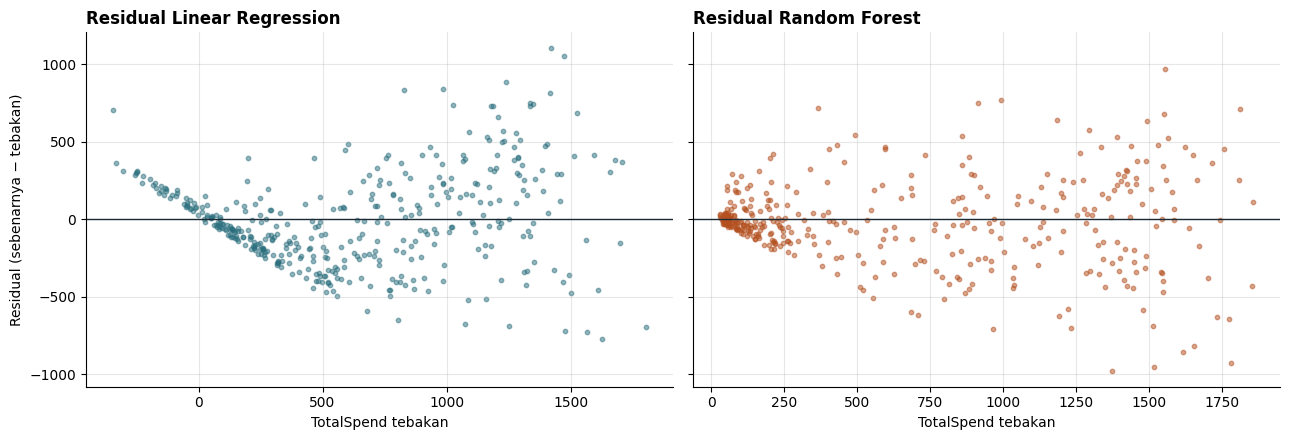

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (nama, warna) in zip(axes, [("Linear Regression", WARNA), ("Random Forest", WARNA_SOROT)]):
    residual = yr_test.values - tebakan_reg[nama]
    ax.scatter(tebakan_reg[nama], residual, s=10, alpha=0.5, color=warna)
    ax.axhline(0, color="#1B2A35", linewidth=1)
    ax.set_title(f"Residual {nama}", loc="left", fontweight="bold")
    ax.set_xlabel("TotalSpend tebakan")
axes[0].set_ylabel("Residual (sebenarnya − tebakan)")
plt.tight_layout()
plt.show()

💬 **Amati:**

1. Model yang baik punya residual yang menyebar acak di sekitar garis 0. Apakah sebarannya merata, atau makin melebar ke kanan?
2. Pada Linear Regression, apa yang terjadi di kiri (tebakan mendekati atau di bawah 0)?

### 8.5 Meleset per segmen

In [23]:
segmen_uji = df.loc[Xr_test.index, "NamaSegmen"].values

per_segmen = pd.DataFrame({
    "segmen": segmen_uji,
    "sebenarnya": yr_test.values,
    "meleset_RF": np.abs(yr_test.values - tebakan_reg["Random Forest"]),
}).groupby("segmen").agg(jumlah=("sebenarnya", "size"),
                          belanja_rata2=("sebenarnya", "mean"),
                          MAE_RF=("meleset_RF", "mean"))
per_segmen["MAE_sebagai_%_belanja"] = per_segmen["MAE_RF"] / per_segmen["belanja_rata2"] * 100
per_segmen.round(0)

,jumlah,belanja_rata2,MAE_RF,MAE_sebagai_%_belanja
segmen,,,,
Hemat,169,81.0,80.0,99.0
Keluarga Mapan,102,848.0,242.0,29.0
Pemburu Diskon,40,561.0,217.0,39.0
Premium,95,1331.0,300.0,23.0


💬 **Diskusi:** di segmen mana meleset paling besar dalam angka? Dalam persen? Kenapa satu angka MAE untuk semua pelanggan bisa menyembunyikan hal ini?

---
## 9. Kartu skor model untuk direksi

Ringkas hasil evaluasi dalam satu tabel yang bisa dibaca orang non-teknis.

In [24]:
auc_logreg = roc_auc_score(y_uji, peluang)
gain30 = persen_tertangkap[int(len(y_urut) * 0.30) - 1]

kartu_skor = pd.DataFrame([
    {"pertanyaan": "Dari pelanggan yang dipilih model, berapa % yang merespons?", "ukuran": "Precision (LogReg, batas 0,5)",
     "nilai": f"{precision_score(y_uji, tebakan):.0%}"},
    {"pertanyaan": "Berapa % responden yang ditemukan?", "ukuran": "Recall (LogReg, batas 0,5)",
     "nilai": f"{recall_score(y_uji, tebakan):.0%}"},
    {"pertanyaan": "Jika ingin menemukan lebih banyak responden?", "ukuran": 'Recall (LogReg "balanced")',
     "nilai": f"{recall_score(y_test, tebakan_seimbang):.0%}"},
    {"pertanyaan": "Seberapa baik model mengurutkan pelanggan?", "ukuran": "ROC-AUC",
     "nilai": f"{auc_logreg:.3f}"},
    {"pertanyaan": "Menghubungi 30% pelanggan teratas menangkap berapa % responden?", "ukuran": "Gain 30%",
     "nilai": f"{gain30:.0f}%"},
    {"pertanyaan": "Perkiraan belanja 2 tahun rata-rata meleset berapa?", "ukuran": "MAE (Random Forest)",
     "nilai": f"{tabel_reg.loc['Random Forest', 'MAE']:.0f}"},
    {"pertanyaan": "Seberapa jauh lebih baik daripada menebak rata-rata?", "ukuran": "R² (Random Forest)",
     "nilai": f"{tabel_reg.loc['Random Forest', 'R2']:.2f}"},
])
kartu_skor

,pertanyaan,ukuran,nilai
0,"Dari pelanggan yang dipilih model, berapa % ya...","Precision (LogReg, batas 0,5)",67%
1,Berapa % responden yang ditemukan?,"Recall (LogReg, batas 0,5)",39%
2,Jika ingin menemukan lebih banyak responden?,"Recall (LogReg ""balanced"")",76%
3,Seberapa baik model mengurutkan pelanggan?,ROC-AUC,0.875
4,Menghubungi 30% pelanggan teratas menangkap be...,Gain 30%,79%
5,Perkiraan belanja 2 tahun rata-rata meleset be...,MAE (Random Forest),186
6,Seberapa jauh lebih baik daripada menebak rata...,R² (Random Forest),0.81


In [26]:
FILE_KARTU = "kartu_skor_model.csv"
kartu_skor.to_csv(FOLDER + FILE_KARTU, index=False)
print("Tersimpan:", FILE_KARTU)

# OPSIONAL: unduh file ke komputer (hapus tanda # di dua baris berikut)
# from google.colab import files
# files.download(FILE_KARTU)

Tersimpan: kartu_skor_model.csv


---
## 10. Latihan mandiri

**Latihan 1 — Hitung manual.** Dari kolom `tebakan_pohon`, hitung TP, FP, FN, TN, lalu precision, recall, dan F1 **tanpa** memakai fungsi scikit-learn. Cocokkan hasilnya dengan tabel di bagian 4.3.

In [ ]:
# Tulis jawaban Latihan 1 di sini

**Latihan 2 — F-beta.** `fbeta_score(y, tebakan, beta=2)` memberi bobot recall dua kali lebih penting daripada precision. Hitung F2 untuk LogReg biasa dan LogReg "balanced". Apakah peringkatnya berubah dibanding F1? Kapan F2 cocok dipakai RetailKu?
*Petunjuk:* `from sklearn.metrics import fbeta_score`

In [ ]:
# Tulis jawaban Latihan 2 di sini

**Latihan 3 — Random Forest seimbang.** Latih `RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)` dengan `buat_persiapan(FITUR_ANGKA, scaling=False)`. Bandingkan precision, recall, F1, dan AUC dengan Random Forest biasa (`peluang_hutan`).

In [ ]:
# Tulis jawaban Latihan 3 di sini

**Latihan 4 — Satu kesalahan besar.** Salin `yr_test`, lalu ubah satu nilai menjadi 20.000 (anggap salah input). Hitung ulang MAE dan RMSE untuk Random Forest. Ukuran mana yang berubah lebih drastis? Apa artinya bagi pemilihan ukuran?

In [ ]:
# Tulis jawaban Latihan 4 di sini

**Latihan 5 (tantangan) — Kurva gain dua model.** Gambar kurva gain Logistic Regression dan Random Forest dalam satu grafik. Pada 20% pelanggan teratas, model mana yang menangkap lebih banyak responden? Apakah ini sejalan dengan AUC dan AP keduanya?

In [ ]:
# Tulis jawaban Latihan 5 di sini

---
## 11. Tugas: kartu skor dan memo untuk direksi

1. Lengkapi **kartu skor** dari bagian 9 dengan satu baris tambahan yang menurutmu penting.
2. Tulis **memo 4–6 kalimat** untuk direksi RetailKu yang menjawab:
   - Kenapa "87,7% akurat" bukan cara yang tepat untuk menilai model ini?
   - Ukuran mana yang kamu sarankan untuk kampanye **email** dan untuk kampanye **katalog**, dan kenapa?
   - Apa arti AUC 0,875 dalam satu kalimat tanpa istilah teknis?
   - Satu keterbatasan perkiraan belanja (regresi) yang perlu diketahui tim CRM.

---
## Rangkuman

| Konsep | Inti | Alat |
|---|---|---|
| TP, FP, FN, TN | Empat kotak confusion matrix | `confusion_matrix(...).ravel()` |
| Precision | Dari yang dipilih, berapa yang benar | `precision_score` |
| Recall | Dari yang sebenarnya positif, berapa yang ditemukan | `recall_score` |
| F1 | Rata-rata harmonik precision dan recall | `f1_score`, `classification_report` |
| Kelas tidak seimbang | Akurasi bisa turun saat model makin berguna | `class_weight="balanced"` |
| Batas peluang | Menggeser batas = menukar precision dengan recall | `predict_proba`, `precision_recall_curve` |
| ROC-AUC | Kualitas urutan; peluang responden diberi skor lebih tinggi | `roc_curve`, `roc_auc_score` |
| PR-AUC dan gain | Lebih jujur untuk kelas kecil; mudah dijelaskan ke bisnis | `average_precision_score`, kurva gain |
| MAE, RMSE, R², MAPE | Meleset rata-rata, hukuman meleset besar, dibanding rata-rata, persen | `sklearn.metrics` |
| Residual | Di mana dan untuk siapa model meleset | Scatter residual, MAE per segmen |

**Pertemuan berikutnya, Model Evaluation 2:** satu data uji bisa kebetulan mudah atau sulit. Kita belajar **cross-validation**, **tuning** parameter, memilih **batas peluang**, dan **simulasi biaya-manfaat** kampanye ke-7.